# BAB 4: DATA UNDERSTANDING, EDA, & DATA PREPROCESSING

In [ ]:
# Proyek: Klasifikasi Status Gizi dan Deteksi Dini Stunting pada Balita
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight

# Pengaturan gaya visualisasi
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)


# 4.1 MEMUAT DATASET & INSPEKSI STRUKTUR (DATA UNDERSTANDING)

In [ ]:
df = pd.read_csv("/content/data_balita.csv")

print("=== 1. DIMENSI & 5 BARIS PERTAMA DATASET ===")
print(f"Jumlah Baris (Observasi) : {df.shape[0]:,}")
print(f"Jumlah Kolom (Variabel)  : {df.shape[1]}")
display(df.head())

print("\n=== 2. INFORMASI TIPE DATA & NON-NULL ===")
df.info()

print("\n=== 3. STATISTIK DESKRIPTIF (NUMERIK & KATEGORIKAL) ===")
display(df.describe())
display(df.describe(include=["object"]))


=== 1. DIMENSI & 5 BARIS PERTAMA DATASET ===
Jumlah Baris (Observasi) : 120,999
Jumlah Kolom (Variabel)  : 4


,Umur (bulan),Jenis Kelamin,Tinggi Badan (cm),Status Gizi
0,0,laki-laki,44.591973,stunted
1,0,laki-laki,56.705203,tinggi
2,0,laki-laki,46.863358,normal
3,0,laki-laki,47.508026,normal
4,0,laki-laki,42.743494,severely stunted



=== 2. INFORMASI TIPE DATA & NON-NULL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120999 entries, 0 to 120998
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Umur (bulan)       120999 non-null  int64  
 1   Jenis Kelamin      120999 non-null  object 
 2   Tinggi Badan (cm)  120999 non-null  float64
 3   Status Gizi        120999 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.7+ MB

=== 3. STATISTIK DESKRIPTIF (NUMERIK & KATEGORIKAL) ===


,Umur (bulan),Tinggi Badan (cm)
count,120999.000000,120999.000000
mean,30.173803,88.655434
std,17.575119,17.300997
min,0.000000,40.010437
25%,15.000000,77.000000
50%,30.000000,89.800000
75%,45.000000,101.200000
max,60.000000,128.000000


,Jenis Kelamin,Status Gizi
count,120999,120999
unique,2,4
top,perempuan,normal
freq,61002,67755


# 4.2 & 4.3 PEMERIKSAAN KONDISI & KUALITAS DATA

In [ ]:
print("\n=== 4. PENGECEKAN MISSING VALUES ===")
missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Percentage (%)": (df.isnull().sum() / len(df)) * 100
})
display(missing_df)

print("\n=== 5. PENGECEKAN DATA DUPLIKAT ===")
total_rows = len(df)
dup_count = df.duplicated().sum()
dup_pct = (dup_count / total_rows) * 100
print(f"Total Baris      : {total_rows:,}")
print(f"Baris Duplikat   : {dup_count:,} ({dup_pct:.2f}%)")
print(f"Kombinasi Unik   : {total_rows - dup_count:,}")

print("\n=== 6. DISTRIBUSI KELAS TARGET (IMBALANCED DATA CHECK) ===")
target_counts = df["Status Gizi"].value_counts()
target_pct = df["Status Gizi"].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({
    "Jumlah Data": target_counts,
    "Persentase (%)": target_pct.round(2)
})
display(dist_df)


=== 4. PENGECEKAN MISSING VALUES ===


,Missing Count,Percentage (%)
Umur (bulan),0,0.0
Jenis Kelamin,0,0.0
Tinggi Badan (cm),0,0.0
Status Gizi,0,0.0



=== 5. PENGECEKAN DATA DUPLIKAT ===
Total Baris      : 120,999
Baris Duplikat   : 81,574 (67.42%)
Kombinasi Unik   : 39,425

=== 6. DISTRIBUSI KELAS TARGET (IMBALANCED DATA CHECK) ===


,Jumlah Data,Persentase (%)
Status Gizi,,
normal,67755,56.00
severely stunted,19869,16.42
tinggi,19560,16.17
stunted,13815,11.42


# 4.4 EXPLORATORY DATA ANALYSIS (VISUALISASI UNTUK LAPORAN)

/tmp/ipykernel_612/982101021.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_612/982101021.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


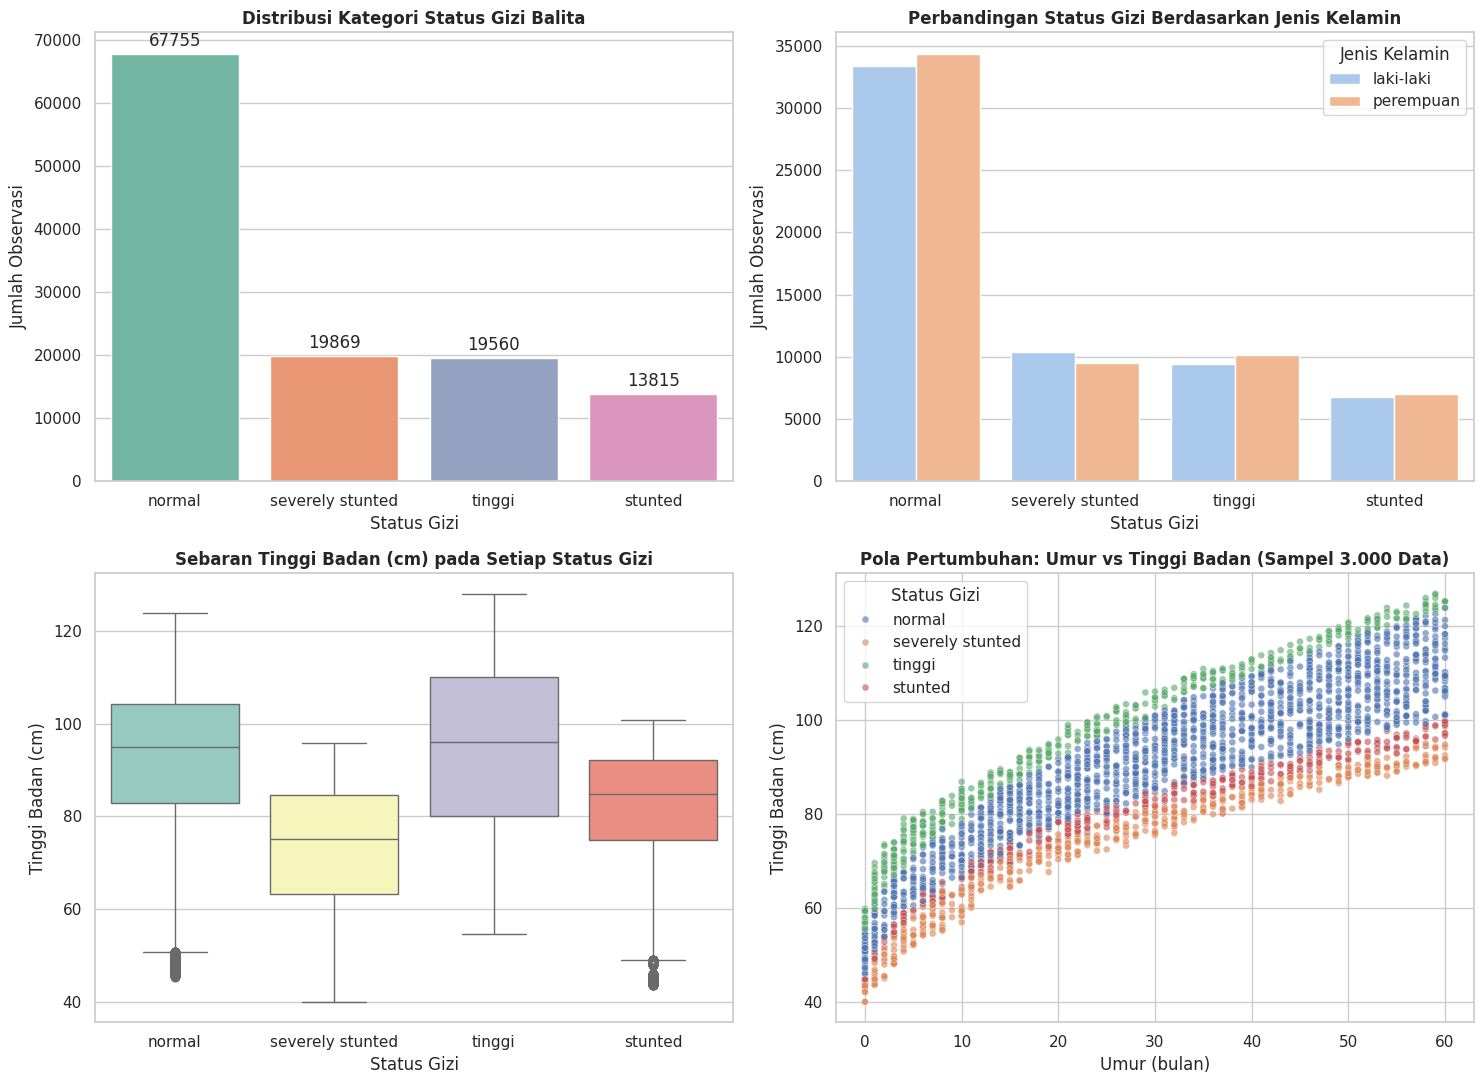

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot 1: Distribusi Kelas Target (Status Gizi)
sns.countplot(
    data=df, x="Status Gizi", order=target_counts.index,
    ax=axes[0, 0], palette="Set2"
)
axes[0, 0].set_title("Distribusi Kategori Status Gizi Balita", fontweight="bold")
axes[0, 0].set_ylabel("Jumlah Observasi")
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%d", padding=3)

# Plot 2: Distribusi Jenis Kelamin terhadap Status Gizi
sns.countplot(
    data=df, x="Status Gizi", hue="Jenis Kelamin",
    order=target_counts.index, ax=axes[0, 1], palette="pastel"
)
axes[0, 1].set_title("Perbandingan Status Gizi Berdasarkan Jenis Kelamin", fontweight="bold")
axes[0, 1].set_ylabel("Jumlah Observasi")

# Plot 3: Boxplot Tinggi Badan (cm) per Kategori Status Gizi (Cek Outliers & Sebaran)
sns.boxplot(
    data=df, x="Status Gizi", y="Tinggi Badan (cm)",
    order=target_counts.index, ax=axes[1, 0], palette="Set3"
)
axes[1, 0].set_title("Sebaran Tinggi Badan (cm) pada Setiap Status Gizi", fontweight="bold")

# Plot 4: Kurva Pertumbuhan (Umur vs Tinggi Badan berdasarkan Status Gizi)
# Mengambil sampel acak 3.000 data agar scatter plot tidak terlalu padat
sample_df = df.sample(n=3000, random_state=42)
sns.scatterplot(
    data=sample_df, x="Umur (bulan)", y="Tinggi Badan (cm)",
    hue="Status Gizi", alpha=0.6, s=25, ax=axes[1, 1], palette="deep"
)
axes[1, 1].set_title("Pola Pertumbuhan: Umur vs Tinggi Badan (Sampel 3.000 Data)", fontweight="bold")

plt.tight_layout()
plt.savefig("eda_stunting_bab4.png", dpi=300)
plt.show()

